# One-Cohort RTM Type 1/2/3 Simulation

This notebook is a paper-facing view of the RTM123 analysis. The expensive simulation work is performed by the small scripts in `scripts/rtm123/`; this notebook reads the saved CSV outputs and displays the resulting tables and figure inline.

In [1]:
from pathlib import Path
from rtm_anatomy.rtm123 import make_figures, make_tables

OUTPUT_DIR = Path('/Users/dgoldenh/Documents/GitHub/anatomy_of_RTM/outputs/rtm123_1m')
make_tables(OUTPUT_DIR)
make_figures(OUTPUT_DIR)

Loaded RTM123 outputs from /Users/dgoldenh/Documents/GitHub/anatomy_of_RTM/outputs/rtm123_1m


## Cohort and Eligibility

The analysis uses one deterministic CHOCOLATES cohort. For each condition, the observed 36-month diary is scanned for the first eligible 2-month baseline window that still leaves a 3-month test period. Eligibility requires a mean baseline rate at or above the condition threshold, at least 3 seizures in each baseline month, and no baseline seizure-free run longer than 25 days.

In [2]:
import pandas as pd
summary = pd.read_csv(OUTPUT_DIR / "paper_table.csv")
summary

condition,label,rtm_type,n_eligible,fraction_eligible,fraction_RTM,delta_fraction_RTM_vs_baseline,MPC,delta_MPC_vs_baseline
baseline_perfect,"Baseline: perfect detector, 4/month",baseline,649098,0.649098,0.539197470951998,0.0,26.66666603088379,0.0
type1_transient_msf,Type 1: transient 2-month mSF change,type1,756179,0.756179,0.5841566613196082,0.0449591903676102,36.842105865478516,10.175439834594727
type2_threshold_8,Type 2: eligibility threshold 8/month,type2,404268,0.404268,0.5799222298079492,0.04072475885595117,29.41176414489746,2.745098114013672
type3_sensitivity_90,"Type 3: sensitivity 90%, FAR 0/day",type3_sensitivity,621144,0.621144,0.5538570766199142,0.014659605667916242,28.484848022460938,1.8181819915771484
type3_sensitivity_80,"Type 3: sensitivity 80%, FAR 0/day",type3_sensitivity,589758,0.589758,0.5710308295945117,0.03183335864251369,33.33333206176758,6.666666030883789
type3_sensitivity_70,"Type 3: sensitivity 70%, FAR 0/day",type3_sensitivity,551890,0.55189,0.59081157477033

## Explainer Figure

This schematic contextualizes the three RTM subtypes using the shared 2-month baseline and 3-month test window.

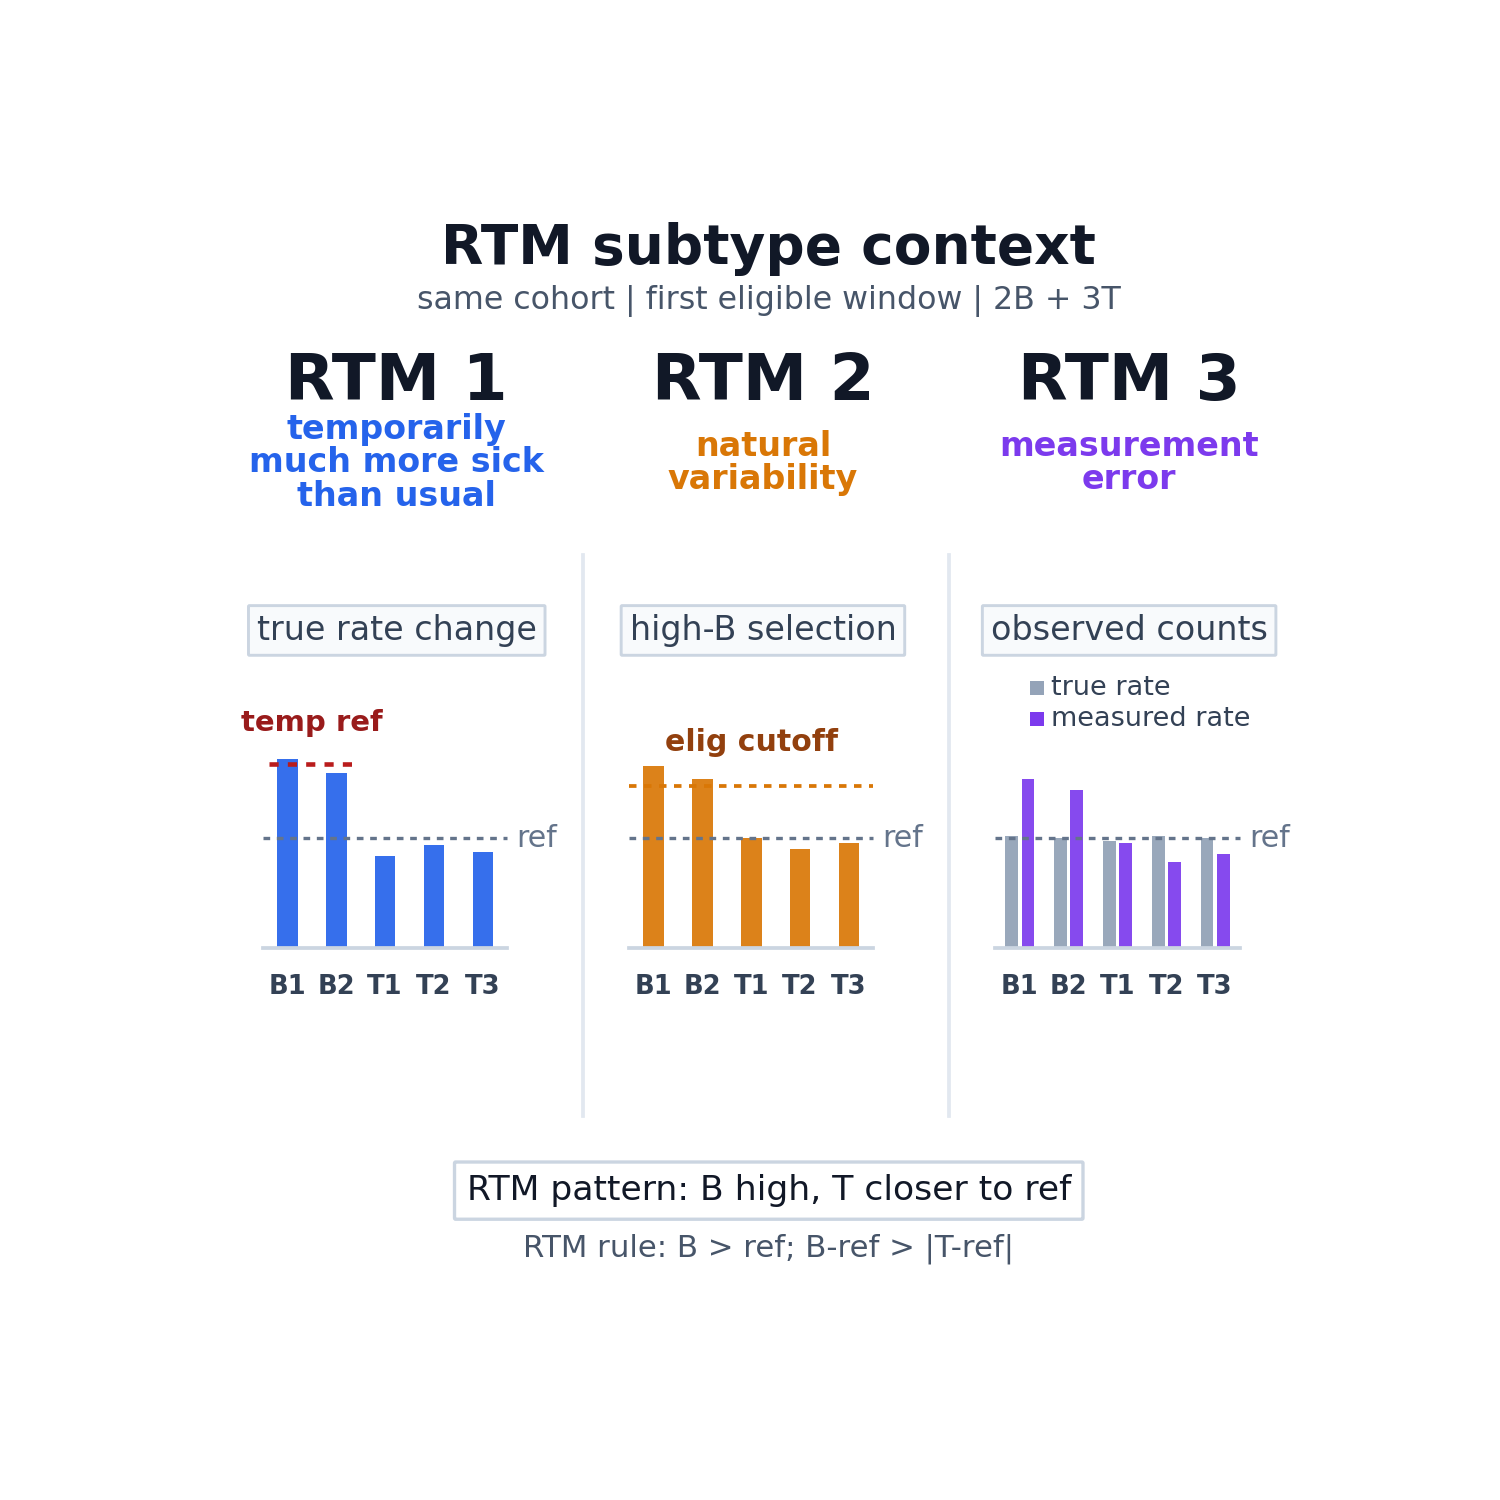

In [3]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / "rtm123_explainer.png")))

## Results Figure

The panels show how small changes to the same initial cohort alter eligibility yield, RTM fraction, and placebo-style MPC. The baseline condition uses a perfect detector and the 4 seizures/month eligibility threshold.

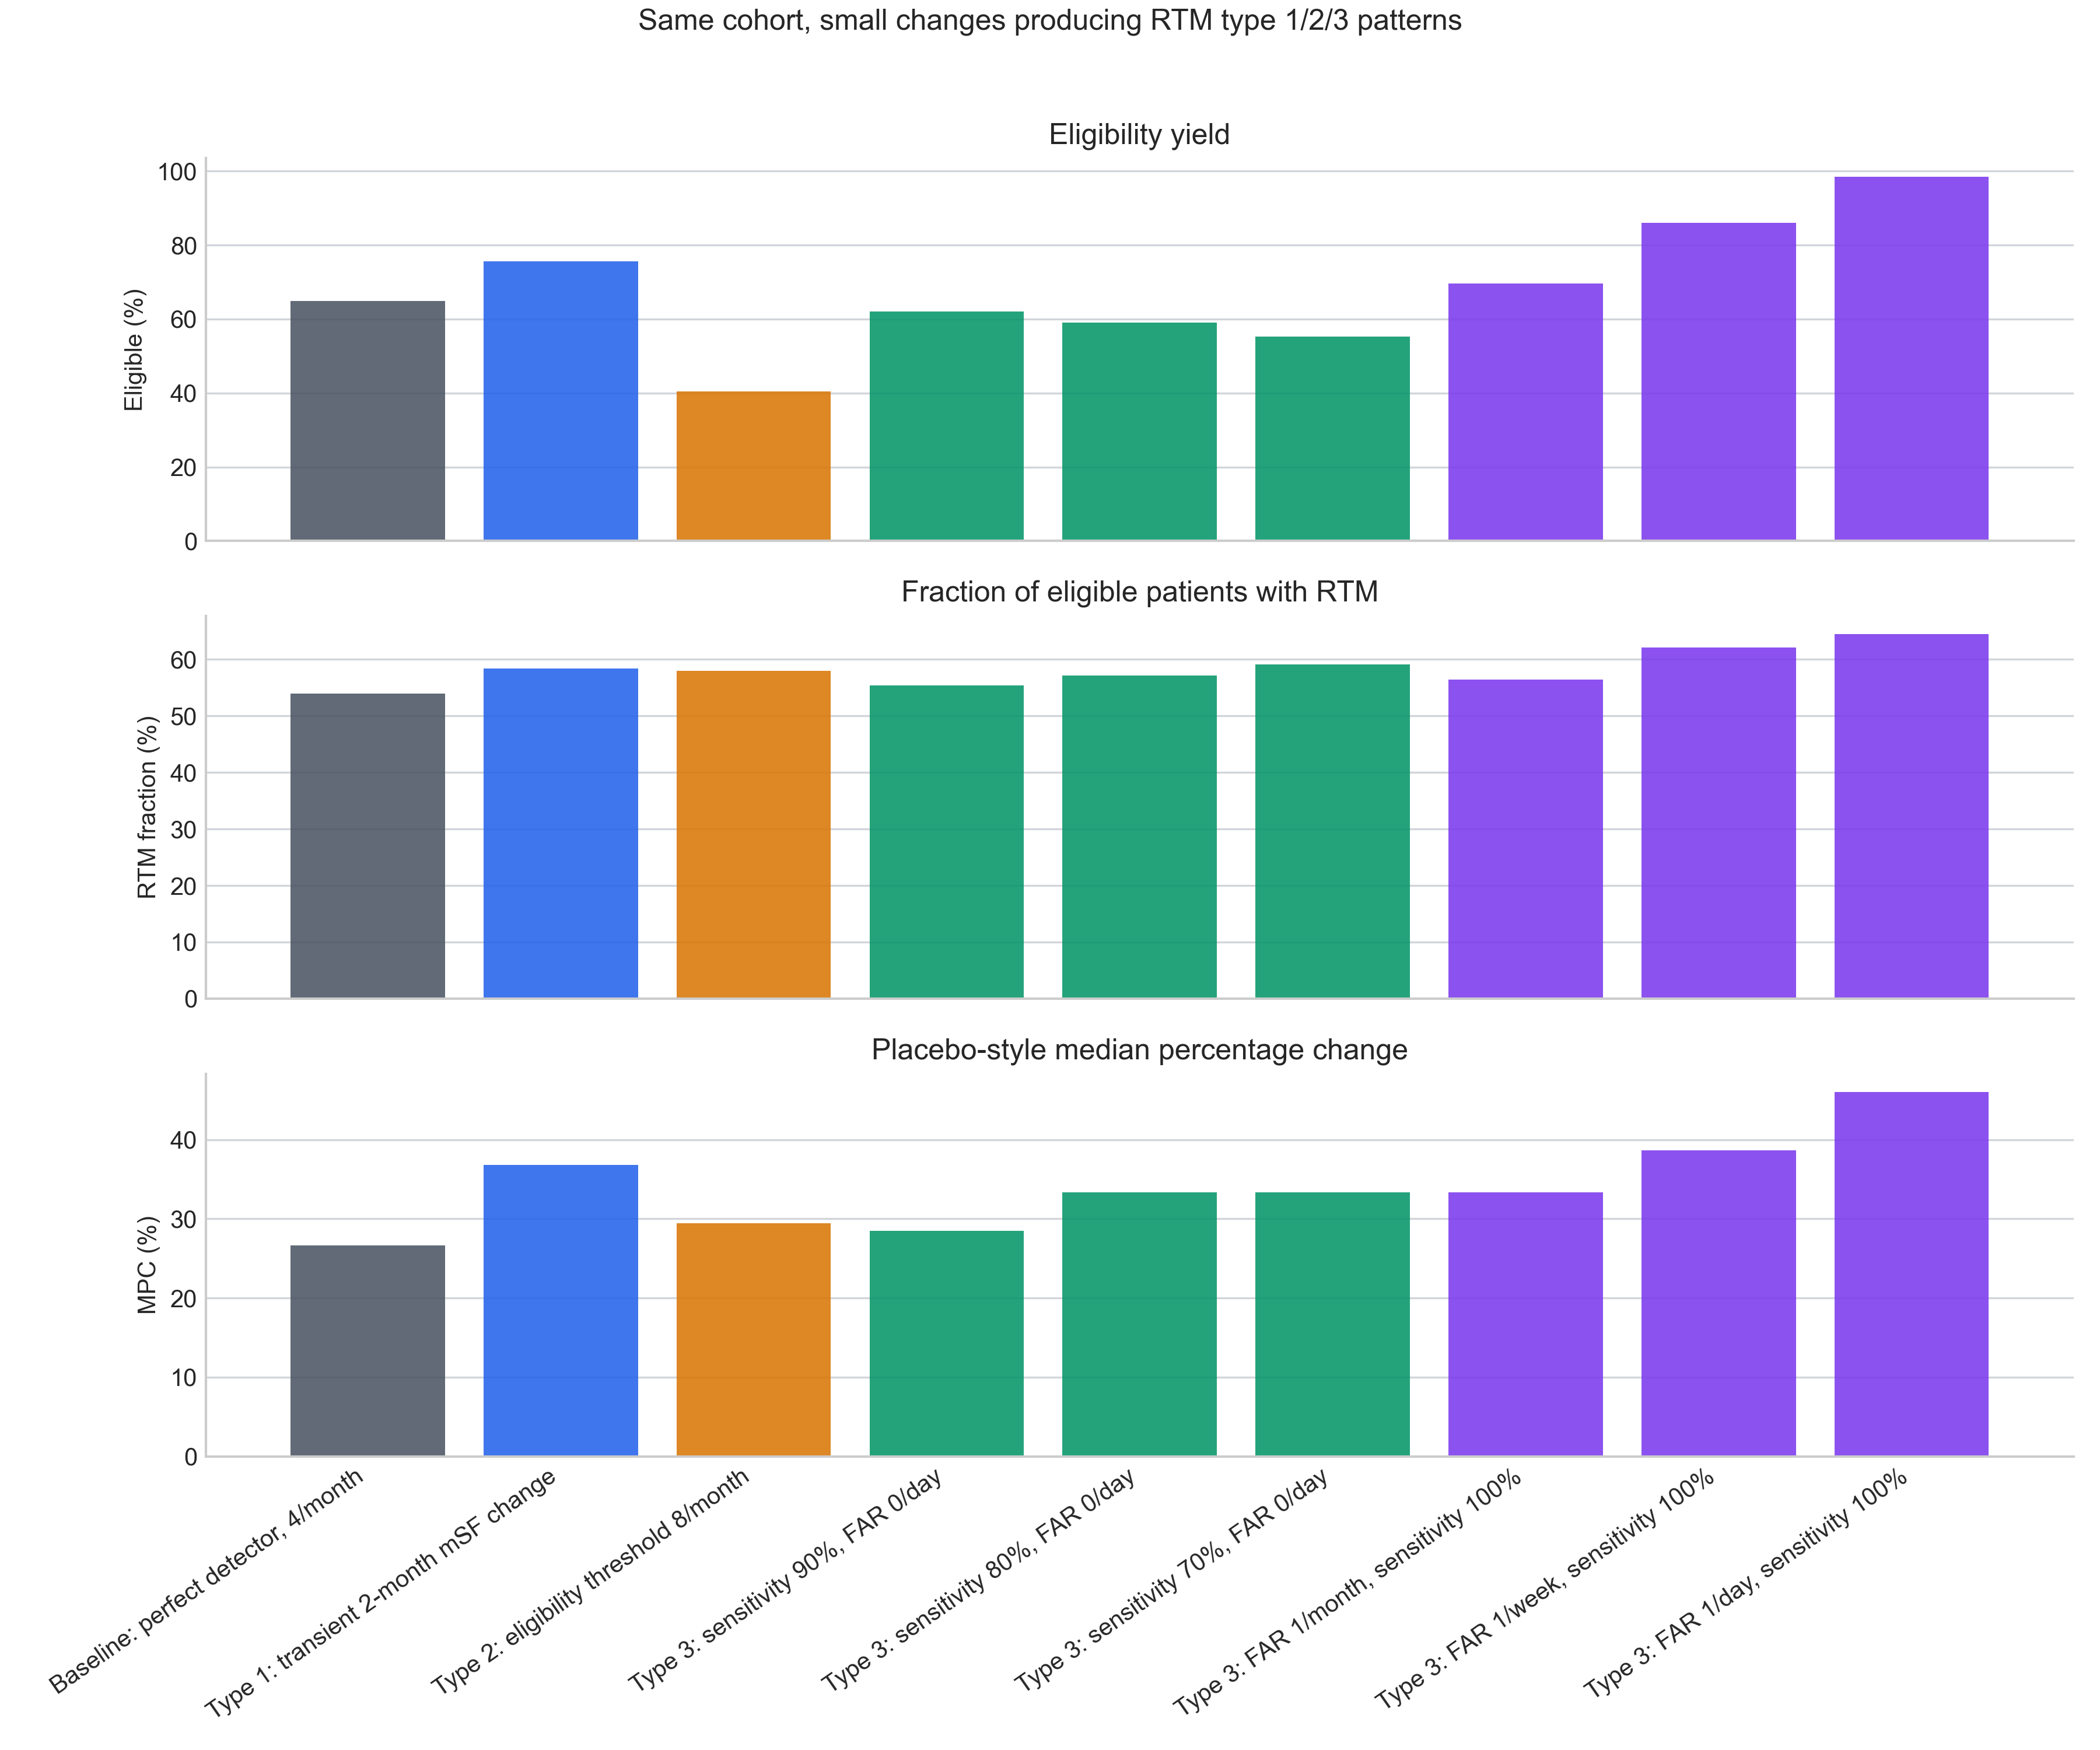

In [4]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / "rtm123_summary.png")))

## Type 1 Shock Stratification

The Type 1 intervention replaces one randomly selected 2-month interval with a newly sampled CHOCOLATES `mSF`, then reverts to the original diary. The table stratifies outcomes by where that transient interval falls relative to the first eligible baseline/test window.

In [5]:
type1 = pd.read_csv(OUTPUT_DIR / "type1_overlap_summary.csv")
type1

condition,overlap,shock_msf_relation,n_raw,n_eligible,fraction_eligible,fraction_RTM,MPC
type1_transient_msf,all,all,1000000,756179,0.756179,0.5841566613196082,36.842105865478516
type1_transient_msf,baseline,all,130289,130289,1.0,0.951108689144901,92.59259033203125
type1_transient_msf,baseline_and_test,all,23659,23659,1.0,0.6872648886258929,38.46154022216797
type1_transient_msf,neither,all,546355,546355,1.0,0.5113268845347805,25.925926208496094
type1_transient_msf,not_eligible,all,243821,0,0.0,nan,nan
type1_transient_msf,test,all,55876,55876,1.0,0.39698618369246186,40.0
type1_transient_msf,baseline,higher,122992,122992,1.0,0.9893326395212697,93.33333587646484
type1_transient_msf,baseline,lower,7297,7297,1.0,0.3068384267507195,-5.55555534362793
type1_transient_msf,baseline_and_test,higher,18815,18815,1.0,0.7835769332979006,41.66666793823242
type1_transient_msf,baseline_and_test,lower,4844,4844,1.0,0.31317093311312966,17.287357330322266
type1_transient_msf,neither,higher,163783,163783,1.

## First Eligible Window

This table confirms that eligibility is not assumed to occur immediately. Each condition scans forward and uses the first qualifying 2-month baseline window.

In [6]:
windows = pd.read_csv(OUTPUT_DIR / "first_eligible_windows.csv")
windows

condition,label,first_eligible_month,n_patients,fraction_raw
baseline_perfect,"Baseline: perfect detector, 4/month",-1,350902,0.350902
baseline_perfect,"Baseline: perfect detector, 4/month",0,330389,0.330389
baseline_perfect,"Baseline: perfect detector, 4/month",1,69656,0.069656
baseline_perfect,"Baseline: perfect detector, 4/month",2,55723,0.055723
baseline_perfect,"Baseline: perfect detector, 4/month",3,29971,0.029971
baseline_perfect,"Baseline: perfect detector, 4/month",4,22057,0.022057
baseline_perfect,"Baseline: perfect detector, 4/month",5,16609,0.016609
baseline_perfect,"Baseline: perfect detector, 4/month",6,13523,0.013523
baseline_perfect,"Baseline: perfect detector, 4/month",7,11239,0.011239
baseline_perfect,"Baseline: perfect detector, 4/month",8,9624,0.009624
baseline_perfect,"Baseline: perfect detector, 4/month",9,8546,0.008546
baseline_perfect,"Baseline: perfect detector, 4/month",10,7506,0.007506
baseline_perfect,"Baseline: perfect detector, 4/month",11,6599,0.006599
ba